# 02 — Modèles source (Part II)
Backbone pré-entraîné gelé + régression logistique L2 (λ choisi sur S_val) + temperature scaling. Source : `results/source_<backbone>.json` (`cli/train_source.py`).

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
R, F = ROOT / "results", ROOT / "figures"
pd.set_option("display.precision", 3); pd.set_option("display.width", 200)
def fig(name):
    p = F / f"{name}.png"
    display(Image(str(p))) if p.exists() else print("missing figure:", p.name)
def csv(name):
    p = R / name
    return pd.read_csv(p) if p.exists() else print("missing table:", p.name)

In [2]:
for bb in ['vit_s16', 'resnet50']:
    s = json.load(open(R / f'source_{bb}.json'))
    display(Markdown(f"**{bb}** — λ = {s['selected_lambda']}, T = {s['temperature']:.3f}"))
    display(pd.DataFrame(s['sweep']).T)
    display(pd.DataFrame(s['eval']).T)

**vit_s16** — λ = 0.1, T = 0.502

,val_acc,val_nll
1e-05,0.710,1.615
0.0001,0.714,1.292
0.001,0.724,1.052
0.003,0.730,0.983
0.01,0.738,0.965
0.03,0.750,1.049
0.1,0.758,1.336
0.3,0.730,1.901


,acc,nll,ece
S_val,0.758,0.952,0.044
S_hold,0.762,0.916,0.064
S_test,0.772,0.828,0.047
A_hold,0.688,1.152,0.047
A_test,0.712,1.088,0.045
W_hold,0.752,0.960,0.043
W_test,0.741,0.997,0.035
P_hold,0.710,1.072,0.023
P_test,0.714,1.011,0.040


**resnet50** — λ = 0.0001, T = 1.682

,val_acc,val_nll
1e-05,0.480,3.068
0.0001,0.480,2.471
0.001,0.466,2.085
0.003,0.474,2.051
0.01,0.472,2.253
0.03,0.426,2.717
0.1,0.326,3.473
0.3,0.174,4.085


,acc,nll,ece
S_val,0.480,2.135,0.046
S_hold,0.454,2.116,0.061
S_test,0.492,2.086,0.065
A_hold,0.440,2.358,0.061
A_test,0.446,2.263,0.042
W_hold,0.416,2.280,0.068
W_test,0.453,2.228,0.045
P_hold,0.480,2.224,0.070
P_test,0.457,2.220,0.035


ResNet-50 : les statistiques BN ont été ré-estimées sur S_train avant la sonde linéaire (voir `docs/03_experiments_log.md`) ; sinon toute statistique de batch d'oiseaux casse la tête linéaire, même sans shift.

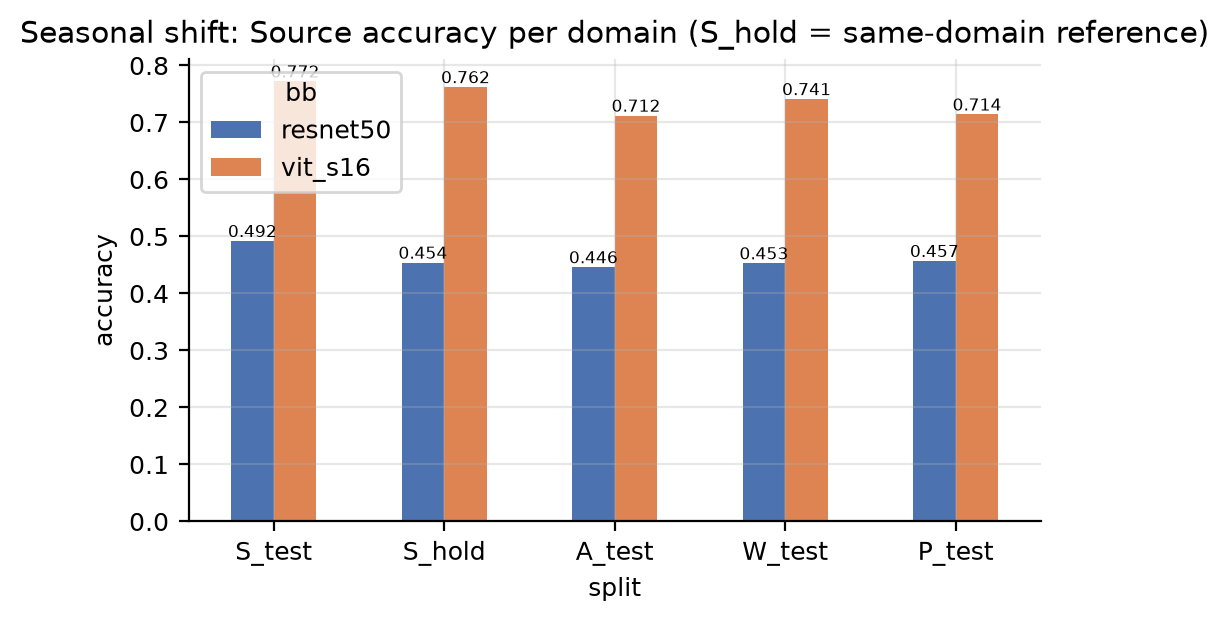

In [3]:
fig('05_shift_seasonal_bars')